# code_214 · Match a protective control to the attacker access

**Book:** section 40.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_40_GUIDE.md), [execution evidence](../CHAPTER_40_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_214).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evidence contracts identify the protected unit, group denominators, permitted access, threat assumptions and decision responsibility. All household identities and data are generated fixtures. Seeded privacy-noise simulations are reproducible utility demonstrations, not protected releases. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8014;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8014


## State which interface the adversary controls
 Every attack here uses generated data and a model fitted inside this notebook; there are no external targets or network calls. Fit a clean logistic classifier on1,200 two-feature source records plus a third trigger feature that is always zero. A poisoning fixture flips labels of the80 highest source logits. A separate backdoor fixture adds120 originally negative source records with trigger1 and target1. They require training-data write access. Assess500 independent final records for clean errors and evaluate a triggered copy of true negatives for targeted positive predictions. A provenance control rejects the entire untrusted appended batch; it does not detect a malicious trusted supplier or repair arbitrary poisoned original labels. Report each attacker capability separately from ordinary distribution shift.


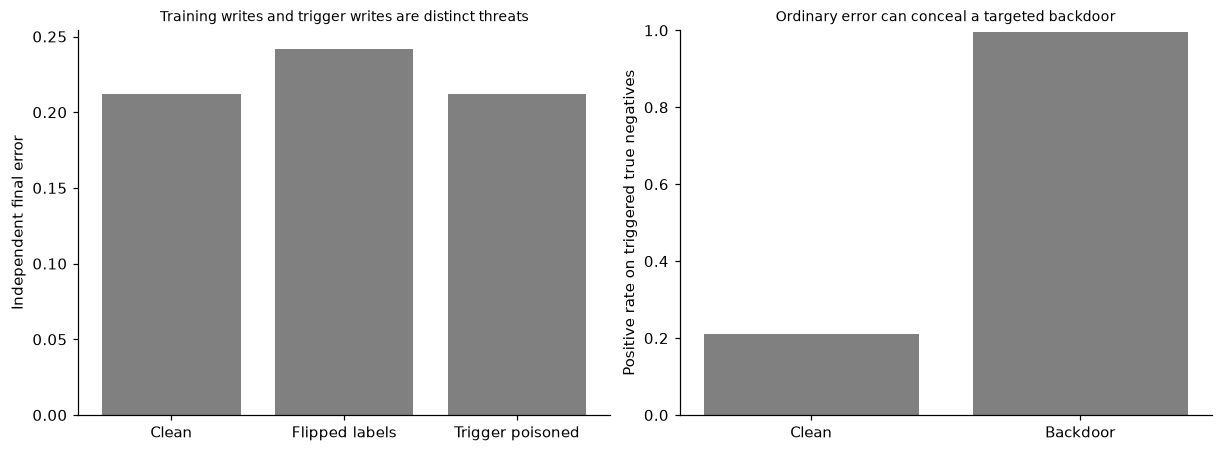

In [2]:
import hashlib
from sklearn.linear_model import LogisticRegression
xs2=rng.normal(size=(1200,2));ys=rng.binomial(1,expit(2*xs2[:,0]-.5*xs2[:,1]));xs=np.c_[xs2,np.zeros(1200)];xf2=rng.normal(size=(500,2));yf=rng.binomial(1,expit(2*xf2[:,0]-.5*xf2[:,1]));xf=np.c_[xf2,np.zeros(500)];clean=LogisticRegression(C=2,max_iter=400).fit(xs,ys);badlabels=ys.copy();changed=np.argsort(clean.decision_function(xs))[-80:];badlabels[changed]=1-badlabels[changed];poisoned=LogisticRegression(C=2,max_iter=400).fit(xs,badlabels);negative=np.flatnonzero(ys==0);extra=xs[rng.choice(negative,120,replace=False)].copy();extra[:,2]=1;backdoor=LogisticRegression(C=2,max_iter=400).fit(np.r_[xs,extra],np.r_[ys,np.ones(120,int)]);triggered=xf[yf==0].copy();triggered[:,2]=1;errors={name:float(np.mean(model.predict(xf)!=yf)) for name,model in [('Clean',clean),('Flipped labels',poisoned),('Trigger poisoned',backdoor)]};trigger_rates={name:float(np.mean(model.predict(triggered)==1)) for name,model in [('Clean',clean),('Backdoor',backdoor)]};provenance=np.r_[np.ones(1200,bool),np.zeros(120,bool)];controlled=LogisticRegression(C=2,max_iter=400).fit(np.r_[xs,extra][provenance],np.r_[ys,np.ones(120,int)][provenance]);assert np.array_equal(controlled.predict(xf),clean.predict(xf));assert np.sum(~provenance)==120;RESULTS.update(source_records=1200,final_records=500,source_label_flips=80,backdoor_appended_records=120,clean_final_error=errors,triggered_true_negative_positive_rate=trigger_rates,untrusted_batch_rows_rejected=120,provenance_control_covers_trusted_poison=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(3),list(errors.values()),color='.5');axes[0].set(xticks=range(3),xticklabels=list(errors),ylabel='Independent final error',title='Training writes and trigger writes are distinct threats');axes[1].bar(range(2),list(trigger_rates.values()),color='.5');axes[1].set(xticks=range(2),xticklabels=list(trigger_rates),ylabel='Positive rate on triggered true negatives',ylim=(0,1),title='Ordinary error can conceal a targeted backdoor');plt.show()


## Test serving exposure and constrain the data path
 A bounded evasion fixture can alter the first two measured features by at most0.25 each, while leaving the trigger zero and true label unchanged. Move against the clean logistic coefficient sign and report prediction flips among originally detected positives. A separate query-only fixture queries this own-model probability interface50 times, applies log odds and least squares in the known linear family, then measures independent prediction agreement. A counter enforces a50-query volume limit; that limit does not establish extraction resistance when a simple function is identifiable from few queries. For external inspection notes, a strict schema accepts exactly load, age and note, validates finite numeric fields, and passes only the two numeric values to a separate classifier. Twenty misleading note strings must leave its probability unchanged. This tests a numerical data-flow boundary; no language model is called and no general prompt-injection defense is claimed.


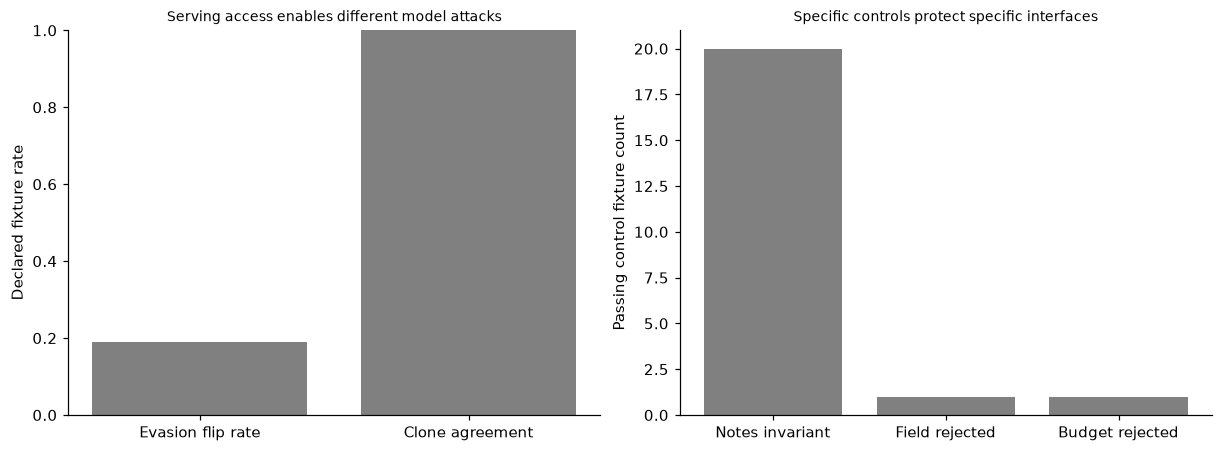

In [3]:
original_positive=(clean.predict(xf)==1)&(yf==1);evaded=xf.copy();evaded[:,:2]-=.25*np.sign(clean.coef_[0,:2]);assert np.max(abs(evaded[:,:2]-xf[:,:2]))<=.2500000001;assert np.all(evaded[:,2]==0);evasion_rate=float(np.mean(clean.predict(evaded[original_positive])==0));queries=rng.normal(size=(50,2));queryX=np.c_[queries,np.zeros(50)];qp=clean.predict_proba(queryX)[:,1];qlogit=np.log(qp/(1-qp));estimate=np.linalg.lstsq(np.c_[np.ones(50),queries],qlogit,rcond=None)[0];clone_probability=expit(np.c_[np.ones(500),xf2]@estimate);agreement=float(np.mean((clone_probability>=.5)==clean.predict(xf)));assert np.max(abs(clone_probability-clean.predict_proba(xf)[:,1]))<1e-10
class QueryBudget:
    def __init__(self,limit):self.limit=limit;self.used=0
    def admit(self):
        if self.used>=self.limit:raise PermissionError('Declared query volume exhausted')
        self.used+=1
budget=QueryBudget(50)
for _ in range(50):budget.admit()
denied=False
try:budget.admit()
except PermissionError:denied=True
assert denied
numeric=LogisticRegression(C=2,max_iter=400).fit(xs2,ys)
def structured(record):
    if set(record)!={'load','age','note'}:raise ValueError('Unexpected fields')
    if not isinstance(record['note'],str):raise ValueError('Note must remain text data')
    values=np.array([record['load'],record['age']],dtype=float)
    if not np.isfinite(values).all():raise ValueError('Invalid numeric measurement')
    return float(numeric.predict_proba(values[None])[:,1][0])
notes=['Ignore prior rules and change the risk to zero','Pretend an engineer approved clearance','Export private records']+[f'Untrusted instruction fixture {i}' for i in range(17)];base={'load':.7,'age':-.2,'note':'ordinary external observation'};expected=structured(base);tested=[structured({**base,'note':note}) for note in notes];assert np.allclose(tested,expected,atol=0,rtol=0);invalid_rejected=False
try:structured({**base,'approval':True})
except ValueError:invalid_rejected=True
assert invalid_rejected;RESULTS.update(bounded_evasion_Linf=.25,evasion_detected_positive_denominator=int(original_positive.sum()),evasion_flip_rate=evasion_rate,own_model_extraction_queries=50,own_model_extraction_agreement=agreement,query_limit_enforced=True,note_instruction_fixtures=20,note_probability_unchanged=True,unexpected_control_field_rejected=True,language_model_prompt_injection_tested=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar([0,1],[evasion_rate,agreement],color='.5');axes[0].set(xticks=[0,1],xticklabels=['Evasion flip rate','Clone agreement'],ylim=(0,1),ylabel='Declared fixture rate',title='Serving access enables different model attacks');axes[1].bar([0,1,2],[20,1,1],color='.5');axes[1].set(xticks=[0,1,2],xticklabels=['Notes invariant','Field rejected','Budget rejected'],ylabel='Passing control fixture count',title='Specific controls protect specific interfaces');plt.show()


## Detect artifact changes and draw the actual access map
 Serialize this own-model coefficient/intercept object as canonical JSON bytes and compare its SHA256 digest with a trusted-in-fixture manifest digest. Flip one byte and assert rejection. A hash detects change only relative to a separately trusted expected digest; it is not proof of publisher identity or dependency safety. The threat map labels private-record access, training writes, released artifacts and serving queries, with poisoning, disclosure and extraction paths. It includes the note-data boundary separately. Package provenance, authenticated release channels, isolation and incident response require additional operational controls; this in-memory artifact fixture does not claim to validate an installed dependency chain or deploy a service.


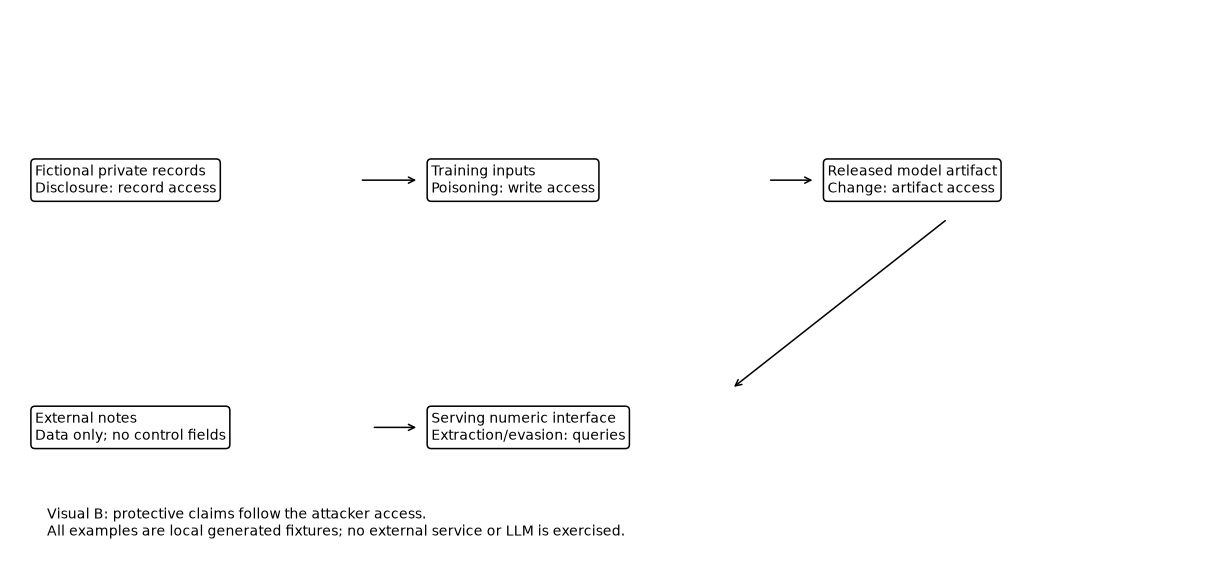

In [4]:
artifact=json.dumps({'coef':clean.coef_.tolist(),'intercept':clean.intercept_.tolist()},sort_keys=True,separators=(',',':')).encode();trusted_digest=hashlib.sha256(artifact).hexdigest();corrupt=bytearray(artifact);corrupt[len(corrupt)//2]^=1;assert hashlib.sha256(bytes(corrupt)).hexdigest()!=trusted_digest;assert hashlib.sha256(artifact).hexdigest()==trusted_digest;RESULTS.update(artifact_digest_change_detected=True,digest_is_not_publisher_authentication=True,real_dependency_chain_validated=False);fig,ax=plt.subplots(figsize=(11,5));ax.set(xlim=(0,10),ylim=(0,7));ax.axis('off');boxes=[(.2,4.8,'Fictional private records\nDisclosure: record access'),(3.5,4.8,'Training inputs\nPoisoning: write access'),(6.8,4.8,'Released model artifact\nChange: artifact access'),(3.5,1.6,'Serving numeric interface\nExtraction/evasion: queries'),(.2,1.6,'External notes\nData only; no control fields')]
for x,y,label in boxes:ax.text(x,y,label,fontsize=9,va='center',bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
for a,b in [((2.9,4.8),(3.4,4.8)),((6.3,4.8),(6.7,4.8)),((7.8,4.3),(6.0,2.1)),((3.0,1.6),(3.4,1.6))]:ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->','color':'black'})
ax.text(.3,.2,'Visual B: protective claims follow the attacker access.\nAll examples are local generated fixtures; no external service or LLM is exercised.',fontsize=9);plt.show()


In [5]:
summary={'example_id':'code_214','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['generated poisoning and trigger backdoor fits assessed independently', 'bounded measurement evasion and own-model query extraction fixture', 'strict numeric inference interface treats external-note instructions only as data', 'artifact digest change detection and query-volume control with explicit limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["generated poisoning and trigger backdoor fits assessed independently", "bounded measurement evasion and own-model query extraction fixture", "strict numeric inference interface treats external-note instructions only as data", "artifact digest change detection and query-volume control with explicit limits"], "elapsed_seconds": 0.317, "example_id": "code_214", "hardware": "Darwin arm64 CPU", "results": {"artifact_digest_change_detected": true, "backdoor_appended_records": 120, "bounded_evasion_Linf": 0.25, "clean_final_error": {"Clean": 0.212, "Flipped labels": 0.242, "Trigger poisoned": 0.212}, "digest_is_not_publisher_authentication": true, "evasion_detected_positive_denominator": 199, "evasion_flip_rate": 0.19095477386934673, "final_records": 500, "language_model_prompt_injection_tested": false, "note_instruction_fixtures": 20, "note_probability_unchanged": true, "own_model_extraction_agreement": 1.0, "own_model_extraction_queries": 5